In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import accuracy_score




In [47]:
df = pd.read_csv("loan_approval_dataset.csv")


df.columns = df.columns.str.strip()


for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()

print(df["loan_status"].value_counts())
print(df["education"].unique())
print(df["self_employed"].unique())

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64
<StringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


/var/folders/4s/3q6mq_h91sq83vkdwgvsjrgc0000gn/T/ipykernel_2050/1728904134.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes(include="object").columns:


In [48]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [49]:
print(df.shape)

df.info()

(4269, 13)
<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [50]:
print(df.isnull().sum())                 
print("Duplicates:", df.duplicated().sum())
print(df.describe().T)
print(df["loan_status"].value_counts(normalize=True) * 100)




loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64
Duplicates: 0
                           count          mean           std       min  \
loan_id                   4269.0  2.135000e+03  1.232498e+03       1.0   
no_of_dependents          4269.0  2.498712e+00  1.695910e+00       0.0   
income_annum              4269.0  5.059124e+06  2.806840e+06  200000.0   
loan_amount               4269.0  1.513345e+07  9.043363e+06  300000.0   
loan_term                 4269.0  1.090045e+01  5.709187e+00       2.0   
cibil_score               4269.0  5.999361e+02  1.724304e+02     300.0   
residential_assets_value  4269.0  7.472617e+06  6.503637e+06 -100

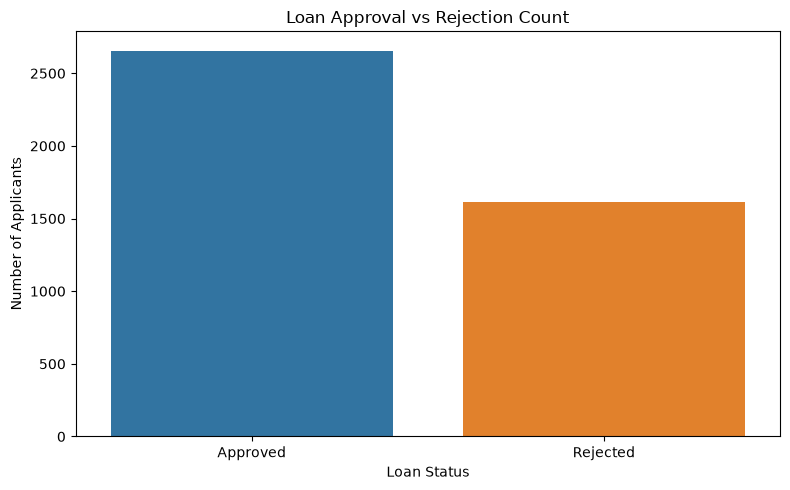

In [51]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="loan_status",
    hue="loan_status"
)

plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.title("Loan Approval vs Rejection Count")
plt.tight_layout()
plt.show()

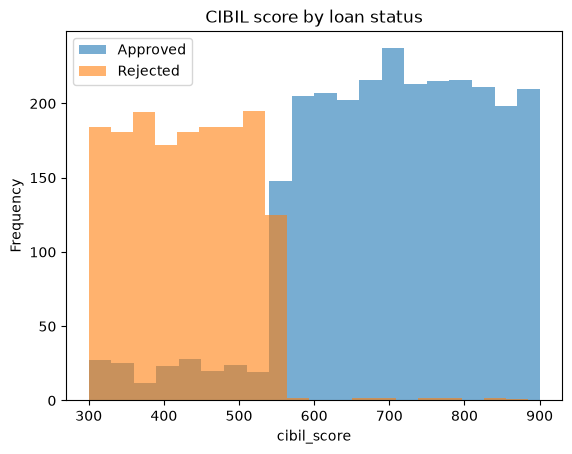

In [52]:
df.groupby("loan_status")["cibil_score"].plot(kind="hist", bins=20, alpha=0.6, legend=True)
plt.xlabel("cibil_score")
plt.title("CIBIL score by loan status")
plt.show()

In [53]:
df = df.drop(columns=["loan_id"]).drop_duplicates()          
df["loan_status"] = (df["loan_status"] == "Approved").astype(int)   
df = pd.get_dummies(df, columns=["education", "self_employed"], drop_first=True)

print(df.corr()["loan_status"].sort_values(ascending=False))

loan_status                 1.000000
cibil_score                 0.770518
loan_amount                 0.016150
commercial_assets_value     0.008246
self_employed_Yes           0.000345
education_Not Graduate     -0.004918
bank_asset_value           -0.006778
residential_assets_value   -0.014367
income_annum               -0.015189
luxury_assets_value        -0.015465
no_of_dependents           -0.018114
loan_term                  -0.113036
Name: loan_status, dtype: float64


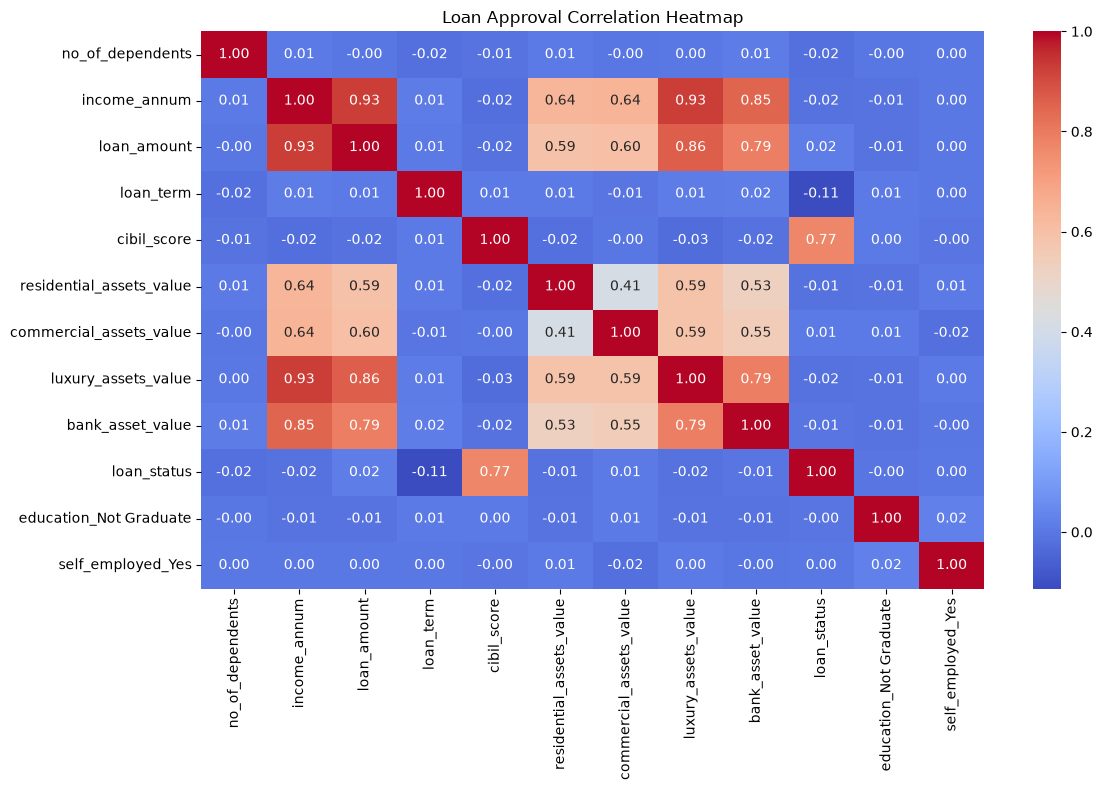

In [54]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Loan Approval Correlation Heatmap")
plt.tight_layout()
plt.show()

In [55]:
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (3415, 11) Test: (854, 11)


In [56]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000))
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['no_of_dependents','income_annum','loan_amount',...,'bank_asset_value', 'education_Not Graduate','self_employed_Yes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [57]:
pred = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, pred), 4))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["Rejected", "Approved"]))

Test accuracy: 0.9133
[[278  45]
 [ 29 502]]
              precision    recall  f1-score   support

    Rejected       0.91      0.86      0.88       323
    Approved       0.92      0.95      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.90      0.91       854
weighted avg       0.91      0.91      0.91       854



In [58]:
new_applicants = pd.DataFrame([
    {"no_of_dependents": 2, "income_annum": 6000000, "loan_amount": 15000000, "loan_term": 12,
     "cibil_score": 750, "residential_assets_value": 5000000, "commercial_assets_value": 3000000,
     "luxury_assets_value": 14000000, "bank_asset_value": 5000000,
     "education_Not Graduate": 0, "self_employed_Yes": 0},
    {"no_of_dependents": 4, "income_annum": 2000000, "loan_amount": 20000000, "loan_term": 18,
     "cibil_score": 400, "residential_assets_value": 1000000, "commercial_assets_value": 500000,
     "luxury_assets_value": 4000000, "bank_asset_value": 1000000,
     "education_Not Graduate": 1, "self_employed_Yes": 1},
])
new_applicants = new_applicants[X.columns]    
labels = model.predict(new_applicants)
probs = model.predict_proba(new_applicants)[:, 1]

for i, (lab, p) in enumerate(zip(labels, probs), start=1):
    print(f"Applicant {i}: {'Approved' if lab == 1 else 'Rejected'}  (approval probability: {p:.1%})")

Applicant 1: Approved  (approval probability: 98.3%)
Applicant 2: Rejected  (approval probability: 9.5%)


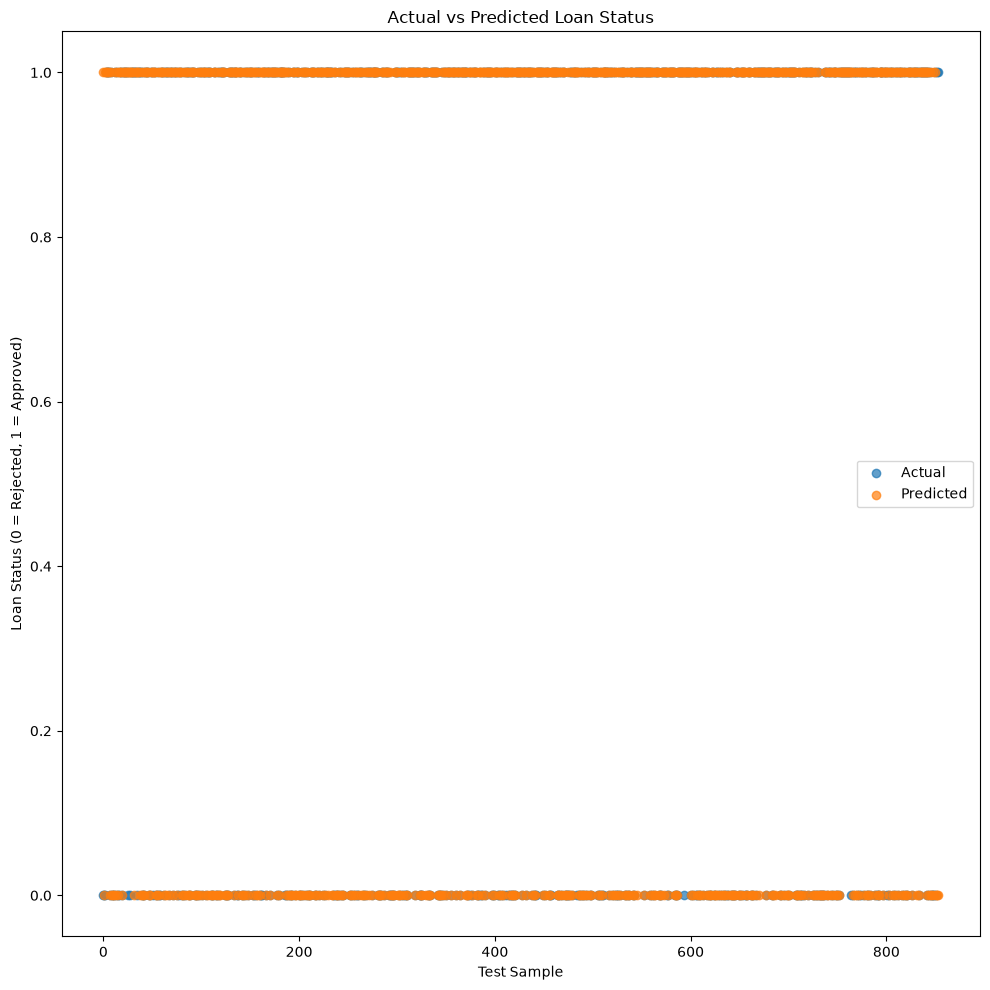

Accuracy Score: 0.9133489461358314
Accuracy Percentage: 91.33 %


In [59]:

y_pred = model.predict(X_test)

plt.figure(figsize=(10, 10))

plt.scatter(range(len(y_test)), y_test,
            label="Actual", alpha=0.7)

plt.scatter(range(len(pred)), pred,
            label="Predicted", alpha=0.7)

plt.xlabel("Test Sample")
plt.ylabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.title("Actual vs Predicted Loan Status")
plt.legend()
plt.tight_layout()
plt.show()

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")
